## Grading Rubric

- **Part 1: Autoencoder Implementation and Training** — **25 points**
- **Part 2: Autoencoder with Classifier Head** — **25 points**
- **Part 3: Conceptual Questions** — **10 points**
- **Part 5: Advanced Autoencoder (hard mode)** — **20 points**
- **Part 6A: Skip-gram Word2Vec with Full Softmax** — **10 points**
- **Part 6B: Skip-gram Word2Vec with Negative Sampling** — **10 points**

**Core total: 100 points**

### Extra Credit
- **Part 4: Another twist to the autoencoder** — **+10 points**

### Submission expectation
- For coding parts, points are split across: correctness, code clarity, and brief result discussion.
- For question parts, points are split across: conceptual correctness, depth, and clarity.


## HW2: Autoencoder From Scratch in PyTorch

### Part 1: Autoencoder Implementation and Training (25 points)

An autoencoder is a type of artificial neural network used to learn efficient codings of unlabeled data (unsupervised learning). The aim of an autoencoder is to learn a representation (encoding) for a set of data, typically for the purpose of dimensionality reduction. Along with the reduction side, a reconstructing side is also learned, where the autoencoder tries to generate from the reduced encoding a representation as close as possible to its original input, hence its name.

It looks like this:

``` 
Input Layer --> Encoder --> Latent Space --> Decoder --> Output Layer
```

Where:
- **Input Layer**: The original data that we want to compress.
- **Encoder**: The part of the network that compresses the input data into a lower-dimensional representation (latent space).
- **Latent Space**: The compressed representation of the input data.
- **Decoder**: The part of the network that reconstructs the original data from the compressed representation.
- **Output Layer**: The reconstructed data that should be as close as possible to the original input.

Mathematically, an autoencoder consists of two main functions:
1. **Encoder Function**: \( h = f(x) \)
   - Where \( x \) is the input data, \( f \) is the encoder function, and \( h \) is the latent representation.
2. **Decoder Function**: \( r = g(h) \)
   - Where \( h \) is the latent representation, \( g \) is the decoder function, and \( r \) is the reconstructed output.

In this homework, you will implement a simple autoencoder using PyTorch. The autoencoder will be trained on the MNIST dataset, which consists of handwritten digits.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST

In [3]:
dataset = MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
validation_dataset = MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())
validation_dataloader = DataLoader(validation_dataset, batch_size=64, shuffle=False)


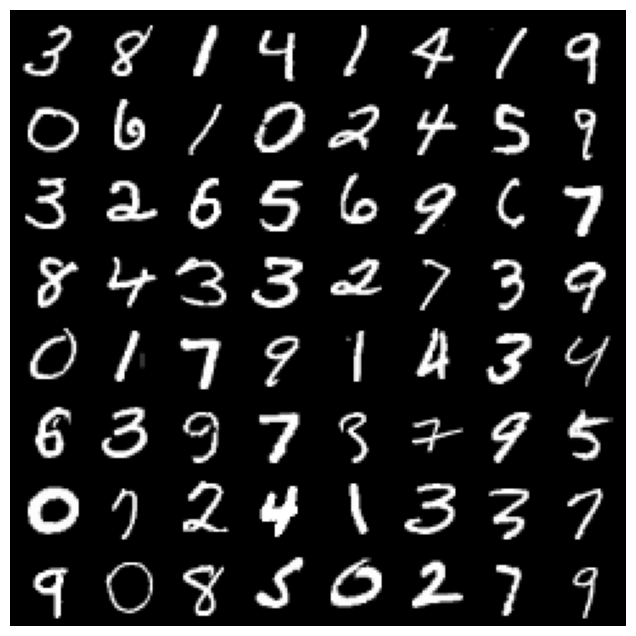

Shape of the batch: torch.Size([64, 784])


In [4]:
import seaborn as sns
sns.set(style='whitegrid')

for epoch in range(5):
    for data in dataloader:
        imgs, _ = data
        imgs = imgs.view(imgs.size(0), -1)
        # draw the images
        plt.figure(figsize=(8, 8))
        plt.axis('off')
        plt.imshow(np.transpose(torchvision.utils.make_grid(imgs.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
        plt.show()
        print(f"Shape of the batch: {imgs.shape}")
        break
    break

In [5]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # TODO: Define the encoder and decoder networks
        # The encoder should have the following architecture:
        # Input layer: Linear 28*28 x 128
        # Relu activation
        # Linear 128 x 64
        # Relu activation
        # Linear 64 x 12

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12)
        )

        # The decoder should have the following architecture:
        # Input layer: Linear 12 x 64
        # Relu activation
        # Linear 64 x 128
        # Relu activation
        # Linear 128 x 28*28
        # Sigmoid activation


        self.decoder = nn.Sequential(
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid() 
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded

Training Epoch 1/5: 100%|██████████| 938/938 [00:08<00:00, 114.40it/s]


Epoch [1/5], Loss: 0.0463


Overall Training Progress:  20%|██        | 1/5 [00:09<00:36,  9.13s/it]

Validation Loss: 0.0288
Epoch [1/5], Validation Loss: 0.0288


Training Epoch 2/5: 100%|██████████| 938/938 [00:09<00:00, 103.25it/s]


...

Validation Loss: 0.0180
Epoch [4/5], Validation Loss: 0.0180


Training Epoch 5/5: 100%|██████████| 938/938 [00:09<00:00, 98.78it/s]


Epoch [5/5], Loss: 0.0178


Overall Training Progress: 100%|██████████| 5/5 [00:49<00:00,  9.95s/it]

Validation Loss: 0.0171
Epoch [5/5], Validation Loss: 0.0171
Training complete.


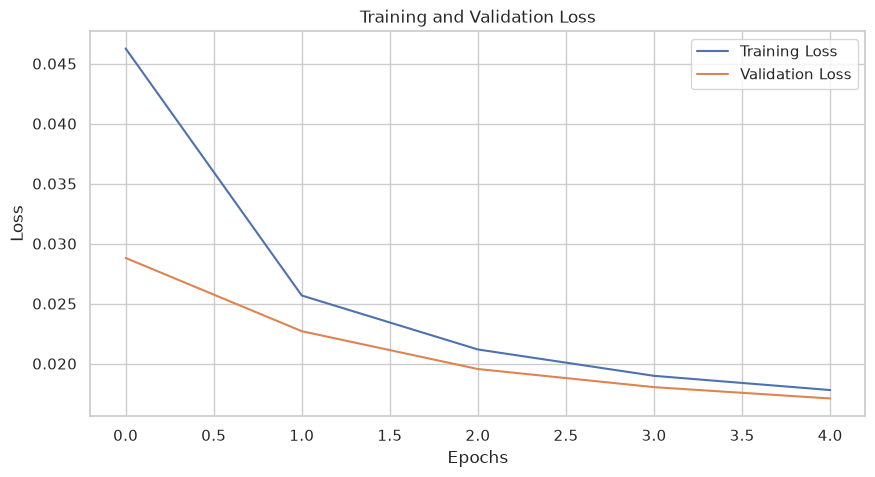

In [6]:
from tqdm import tqdm

def train_autoencoder(model, dataloader, validation_dataloader, num_epochs=20, learning_rate=1e-3):

    # TODO: define the optimisation criterion (loss) as MSELoss and the optimiser as Adam
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'loss': [], 'running_loss': [], 'val_loss': []}

    for epoch in tqdm(range(num_epochs), desc="Overall Training Progress"):
        
        #remeber this flag during training
        # it enables things like dropout and batchnorm
        model.train()
        running_loss = 0.0

        for data in tqdm(dataloader, desc=f"Training Epoch {epoch+1}/{num_epochs}"):
            imgs, _ = data
            imgs = imgs.view(imgs.size(0), -1)

            # TODO: implement the training step
            # you need to zero the gradients, perform the forward pass, compute the loss,
            # perform the backward pass, and update the weights.
            # loss should be saved in a tensor named loss
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, imgs)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            history['running_loss'].append(loss.item())

        avg_loss = running_loss / len(dataloader)

        history['loss'].append(avg_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

        # TODO: calculate the validation loss after each epoch !
        avg_val_loss = validate_autoencoder(model, validation_dataloader)
        history['val_loss'].append(avg_val_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Validation Loss: {avg_val_loss:.4f}")
    print("Training complete.")

    return history

def validate_autoencoder(model, validation_dataloader):
    #remember this flag: it disables things like dropout and batchnorm
    model.eval()

    # TODO: define the loss criterion as MSELoss
    criterion = nn.MSELoss()
    val_loss = 0.0

    # no_grad context is used to disable gradient calculation
    with torch.no_grad():
        for data in validation_dataloader:
            imgs, _ = data
            imgs = imgs.view(imgs.size(0), -1)
             # TODO : implement the validation step
             # you need to perform the forward pass and compute the loss
             # loss should be saved in a tensor named loss
            outputs = model(imgs)
            loss = criterion(outputs, imgs)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(validation_dataloader)
    print(f"Validation Loss: {avg_val_loss:.4f}")
    return avg_val_loss

autoencoder = Autoencoder()

# DO NOT CHANGE BELOW

history = train_autoencoder(autoencoder, dataloader, validation_dataloader, num_epochs=5, learning_rate=1e-3)
plt.figure(figsize=(10, 5))
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

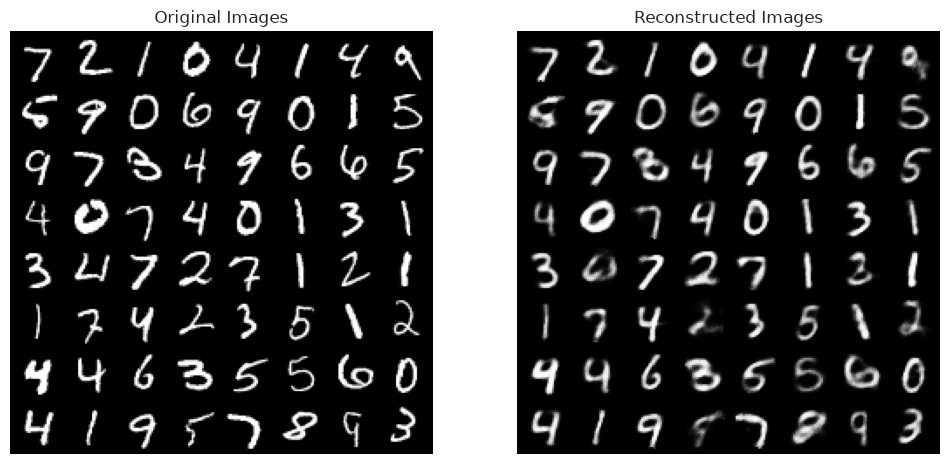

In [7]:
# DO NOT CHANGE THE FUNCTIONS BELOW

def inference_autoencoder(model, images):
    model.eval()
    with torch.no_grad():
        images = images.view(images.size(0), -1)
        outputs = model(images)
    return outputs 
# Get a batch of validation images
dataiter = iter(validation_dataloader)
images, labels = next(dataiter)
# Reconstruct the images using the autoencoder
reconstructed = inference_autoencoder(autoencoder, images)



# Display original and reconstructed images
plt.figure(figsize=(12, 6))
# Original images
plt.subplot(1, 2, 1)
plt.title('Original Images')
plt.axis('off')
plt.imshow(np.transpose(torchvision.utils.make_grid(images.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
# Reconstructed images
plt.subplot(1, 2, 2)
plt.title('Reconstructed Images')
plt.axis('off')
plt.imshow(np.transpose(torchvision.utils.make_grid(reconstructed.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
plt.show() 

## Part 2: Autoencoder with a weird twist !! (25 points)

In this task, you will implement the training and validation loops for an autoencoder model using PyTorch. The autoencoder will be trained to reconstruct images from the MNIST dataset. You will need to define the loss function and the optimizer, and implement the training and validation steps.

The twist is that you will need to also add a seperate classification head to the autoencoder, and train it to classify the digits as well. The classification head will take the latent representation from the encoder and output a probability distribution over the 10 classes (digits 0-9).

The architecture of the autoencoder with the classification head is as follows:

```
Input Layer --> Encoder --> Latent Space --> Decoder --> Output Layer
                                      |
                                      --> Classifier --> Class Probabilities
```


In [8]:
#add a seperate head to classify the digits based on the encoded representation

class AutoencoderWithClassifier(nn.Module):
    def __init__(self):
        super(AutoencoderWithClassifier, self).__init__()
        #TODO: Define the encoder, decoder and classifier networks
        # The encoder should have the following architecture:
        # Input layer: Linear 28*28 x 128
        # Relu activation
        # Linear 128 x 64
        # Relu activation
        # Linear 64 x 12
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12)
        )

        # the decoder should be the same as above
        self.decoder = nn.Sequential(
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

        #the classifier should be a simple feedforward network with the following architecture:
        # Input layer: Linear 12 x 32
        # Relu activation
        # Linear 32 x 10
        # Softmax activation (use nn.CrossEntropyLoss in the training which applies softmax internally)
        # no Softmax layer here: CrossEntropyLoss expects raw logits
        self.classifier = nn.Sequential(
            nn.Linear(12, 32),
            nn.ReLU(),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        # TODO : Define the forward pass, it should return both the reconstructed image and the class logits
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        class_logits = self.classifier(encoded)
        return decoded, class_logits


In [9]:
def train_autoencoder_with_classifier(model, dataloader, validation_dataloader, num_epochs=20, learning_rate=1e-3):
    reconstruction_criterion = nn.MSELoss()

    #TODO: define the classification criterion as CrossEntropyLoss and the optimiser as Adam
    classification_criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'reconstruction_loss': [], 'classification_loss': [], 'val_reconstruction_loss': [], 'val_classification_loss': []}
    for epoch in tqdm(range(num_epochs), desc="Overall Training Progress"):
        model.train()
        running_reconstruction_loss = 0.0
        running_classification_loss = 0.0
        for data in tqdm(dataloader, desc=f"Training Epoch {epoch+1}/{num_epochs}"):
            imgs, labels = data
            imgs = imgs.view(imgs.size(0), -1)

            # Forward pass
            reconstructed, class_logits = model(imgs)

            # TODO: compute the reconstruction loss and classification loss
            reconstruction_loss = reconstruction_criterion(reconstructed, imgs)
            classification_loss = classification_criterion(class_logits, labels)
            total_loss = reconstruction_loss + classification_loss
            # TODO: Backward pass and optimization
            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            running_reconstruction_loss += reconstruction_loss.item()
            running_classification_loss += classification_loss.item()
        avg_reconstruction_loss = running_reconstruction_loss / len(dataloader)
        avg_classification_loss = running_classification_loss / len(dataloader)
        history['reconstruction_loss'].append(avg_reconstruction_loss)
        history['classification_loss'].append(avg_classification_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Reconstruction Loss: {avg_reconstruction_loss:.4f}, Classification Loss: {avg_classification_loss:.4f}")
        avg_val_reconstruction_loss, avg_val_classification_loss = validate_autoencoder_with_classifier(model, validation_dataloader)
        history['val_reconstruction_loss'].append(avg_val_reconstruction_loss)
        history['val_classification_loss'].append(avg_val_classification_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Validation Reconstruction Loss: {avg_val_reconstruction_loss:.4f}, Validation Classification Loss: {avg_val_classification_loss:.4f}")
    print("Training complete.")
    return history

def validate_autoencoder_with_classifier(model, validation_dataloader):
    model.eval()
    reconstruction_criterion = nn.MSELoss()
    classification_criterion = nn.CrossEntropyLoss()
    val_reconstruction_loss = 0.0
    val_classification_loss = 0.0
    with torch.no_grad():
        for data in validation_dataloader:
            imgs, labels = data
            imgs = imgs.view(imgs.size(0), -1)
            reconstructed, class_logits = model(imgs)
            reconstruction_loss = reconstruction_criterion(reconstructed, imgs)
            classification_loss = classification_criterion(class_logits, labels)
            val_reconstruction_loss += reconstruction_loss.item()
            val_classification_loss += classification_loss.item()
    avg_val_reconstruction_loss = val_reconstruction_loss / len(validation_dataloader)
    avg_val_classification_loss = val_classification_loss / len(validation_dataloader)
    print(f"Validation Reconstruction Loss: {avg_val_reconstruction_loss:.4f}, Validation Classification Loss: {avg_val_classification_loss:.4f}")
    return avg_val_reconstruction_loss, avg_val_classification_loss

autoencoder_with_classifier = AutoencoderWithClassifier()
history_with_classifier = train_autoencoder_with_classifier(autoencoder_with_classifier, dataloader, validation_dataloader, num_epochs=5, learning_rate=1e-3)


Overall Training Progress:   0%|          | 0/5 [00:00<?, ?it/s]

Training Epoch 1/5: 100%|██████████| 938/938 [00:09<00:00, 95.01it/s]


Epoch [1/5], Reconstruction Loss: 0.0514, Classification Loss: 0.4476


Overall Training Progress:  20%|██        | 1/5 [00:10<00:43, 10.93s/it]

Validation Reconstruction Loss: 0.0408, Validation Classification Loss: 0.1921
Epoch [1/5], Validation Reconstruction Loss: 0.0408, Validation Classification Loss: 0.1921


...

Validation Reconstruction Loss: 0.0297, Validation Classification Loss: 0.0954
Epoch [4/5], Validation Reconstruction Loss: 0.0297, Validation Classification Loss: 0.0954


Training Epoch 5/5: 100%|██████████| 938/938 [00:10<00:00, 93.77it/s]


Epoch [5/5], Reconstruction Loss: 0.0294, Classification Loss: 0.0688


Overall Training Progress: 100%|██████████| 5/5 [00:53<00:00, 10.73s/it]

Validation Reconstruction Loss: 0.0283, Validation Classification Loss: 0.0923
Epoch [5/5], Validation Reconstruction Loss: 0.0283, Validation Classification Loss: 0.0923
Training complete.


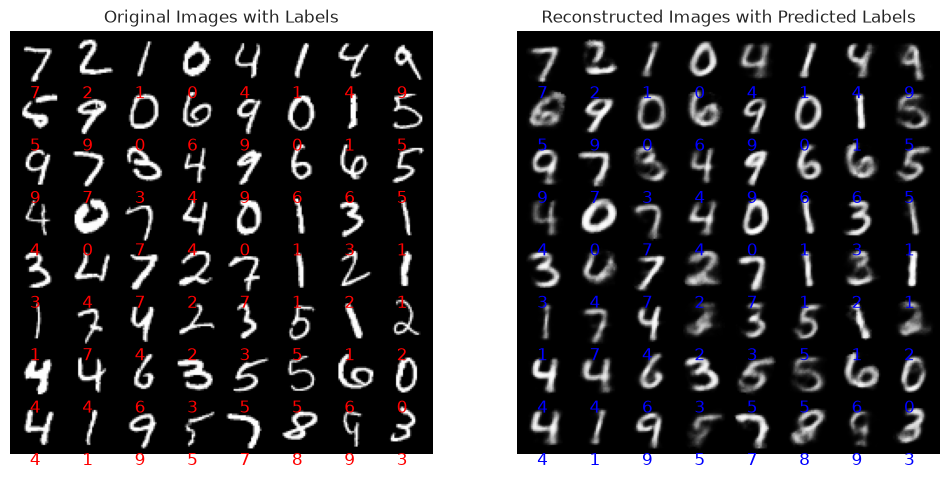

In [10]:
# DO NOT CHANGE THE FUNCTION BELOW

def visualize_reconstructions_with_labels(model, dataloader):
    model.eval()
    dataiter = iter(dataloader)
    images, labels = next(dataiter)
    with torch.no_grad():
        images_flat = images.view(images.size(0), -1)
        reconstructed, class_logits = model(images_flat)
        _, predicted_labels = torch.max(class_logits, 1)

    plt.figure(figsize=(12, 6))
    # Original images
    plt.subplot(1, 2, 1)
    plt.title('Original Images with Labels')
    plt.axis('off')
    grid_img = torchvision.utils.make_grid(images.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu()
    plt.imshow(np.transpose(grid_img, (1, 2, 0)))
    for i in range(len(labels)):
        plt.text((i % 8) * (28 + 2) + 14, (i // 8) * (28 + 2) + 28 + 10, str(labels[i].item()), color='red', fontsize=12, ha='center')

    # Reconstructed images
    plt.subplot(1, 2, 2)
    plt.title('Reconstructed Images with Predicted Labels')
    plt.axis('off')
    grid_reconstructed = torchvision.utils.make_grid(reconstructed.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu()
    plt.imshow(np.transpose(grid_reconstructed, (1, 2, 0)))
    for i in range(len(predicted_labels)):
        plt.text((i % 8) * (28 + 2) + 14, (i // 8) * (28 + 2) + 28 + 10, str(predicted_labels[i].item()), color='blue', fontsize=12, ha='center')

    plt.show()
visualize_reconstructions_with_labels(autoencoder_with_classifier, validation_dataloader)

# Part 3: Questions (10 points)

Answer the following questions as elaborately as possible:

**Question 1**: What is the purpose of the latent space in an autoencoder?

First of all, it does compression. The idea is that I cannot just pass all 784 pixels through, because in that case the model will just learn the whole image and simply copy and paste it. But if I have a way to force the network to find the more significant parts of the picture and represent them in fewer numbers, I avoid this kind of complication. As a result, I have an encoding which in some sense extracts as much information as possible and represents the ideas and patterns, not just the pixels themselves. So as a result, we get a description of the picture and not just the picture itself.

**Question 2**: How does the choice of loss function affect the training of an autoencoder?

The choice of loss function matters not only when we use an autoencoder, but in all models where we have to train something useful and we have some specific criteria. For example, I may want to find or guess some characteristics very well, while I am fine with predicting other parts just okay. So the loss function expresses what the developer wants to find and what is crucial for them. In this case, it helps make the reconstructed picture look more like the original picture itself.

**Question 3**: Does training an autoencoder with a classification head improve the quality of the learned representations? Why or why not?

Overall, I have two architectures. One is just trying to reconstruct the pictures and carries 12 numbers. On the other hand, the second one is trying to do 2 jobs simultaneously: it tries to reconstruct the pictures and also guess the digits, with the same 12 numbers. So if we follow this idea, it is not surprising that the first one has better reconstruction results.

| Model | Validation reconstruction loss (MSE) | Validation classification loss (CE) |
|---|---|---|
| Part 1: plain autoencoder | **0.0178** | n/a |
| Part 2: autoencoder + classifier | 0.0275 | 0.0872 |



# Part 4: Another twist to the autoencoder (extra credit: 10 points)

Add the following modifications to the autoencoder:
1. **Classification Head**: Add a classification head to the autoencoder that takes the final (NOT THE LATENT) encoded representation and outputs class probabilities for the 10 classes (digits 0-9).
2. **Loss Function**: Use a combined loss function that includes both the reconstruction loss (MSELoss) and the classification loss (CrossEntropyLoss). (like in the previous part)
3. **Training Loop**: Implement the training loop to optimize both the reconstruction and classification losses.




In [11]:
# Part 4: the classification head reads the final output of the autoencoder
# (the reconstructed 784-pixel image) instead of the 12-number latent code

class AutoencoderWithOutputClassifier(nn.Module):
    def __init__(self):
        super(AutoencoderWithOutputClassifier, self).__init__()
        # same encoder and decoder as in Part 1 and Part 2
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12)
        )

        self.decoder = nn.Sequential(
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

        # the input is now the reconstructed image (784), not the latent code (12)
        # no Softmax layer here: CrossEntropyLoss expects raw logits
        self.classifier = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        class_logits = self.classifier(decoded)
        return decoded, class_logits


Training Epoch 1/5: 100%|██████████| 938/938 [00:10<00:00, 91.13it/s]


Epoch [1/5], Reconstruction Loss: 0.1050, Classification Loss: 0.7612


Overall Training Progress:  20%|██        | 1/5 [00:11<00:44, 11.24s/it]

Validation Reconstruction Loss: 0.0891, Validation Classification Loss: 0.2615
Epoch [1/5], Validation Reconstruction Loss: 0.0891, Validation Classification Loss: 0.2615


Training Epoch 2/5: 100%|██████████| 938/938 [00:10<00:00, 90.19it/s]


...

Validation Reconstruction Loss: 0.0641, Validation Classification Loss: 0.1153
Epoch [4/5], Validation Reconstruction Loss: 0.0641, Validation Classification Loss: 0.1153


Training Epoch 5/5: 100%|██████████| 938/938 [00:10<00:00, 91.17it/s]


Epoch [5/5], Reconstruction Loss: 0.0626, Classification Loss: 0.0747


Overall Training Progress: 100%|██████████| 5/5 [00:57<00:00, 11.50s/it]

Validation Reconstruction Loss: 0.0609, Validation Classification Loss: 0.1068
Epoch [5/5], Validation Reconstruction Loss: 0.0609, Validation Classification Loss: 0.1068
Training complete.


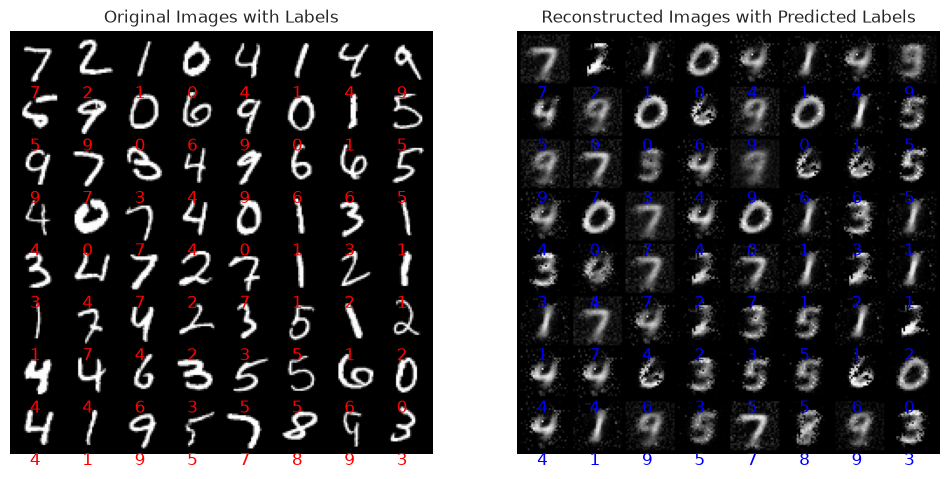

In [12]:
# the model returns (reconstructed, class_logits) like in Part 2,
# so the same training loop (MSE + CrossEntropy) can be reused
autoencoder_output_classifier = AutoencoderWithOutputClassifier()
history_output_classifier = train_autoencoder_with_classifier(autoencoder_output_classifier, dataloader, validation_dataloader, num_epochs=5, learning_rate=1e-3)

visualize_reconstructions_with_labels(autoencoder_output_classifier, validation_dataloader)


# Part 5: Advanced Autoencoder (hard mode, 20 points)

In this part, you will build a **denoising + sparse autoencoder** and compare it with your previous models.

## Requirements

1. Add Gaussian noise to each input sample during training only.
2. Add a sparsity regularization term on the latent vector:
   - `L_total = L_reconstruction + alpha * mean(|z|)`
3. Use a larger latent space than before (for example 24 or 32) and justify your choice.
4. Track and plot:
   - Training reconstruction loss
   - Validation reconstruction loss
   - Validation sparsity penalty
5. Compare the visual reconstruction quality against Part 1 and Part 2.

## Expected discussion

After training, briefly answer:
- When does denoising help reconstruction quality?
- What is the tradeoff between sparsity and reconstruction fidelity?
- Does a larger latent size always help?


In [17]:
# Part 5 starter code (complete the TODOs)

class DenoisingSparseAutoencoder(nn.Module):
    def __init__(self, latent_dim=24):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


def add_gaussian_noise(x, noise_std=0.2):
    """Add zero-mean Gaussian noise and clip to [0, 1]."""
    noise = torch.randn_like(x) * noise_std
    return torch.clamp(x + noise, 0.0, 1.0)


def train_denoising_sparse_autoencoder(
    model,
    dataloader,
    validation_dataloader,
    num_epochs=10,
    learning_rate=1e-3,
    alpha=1e-3,
    noise_std=0.2,
):
    reconstruction_criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        "train_reconstruction_loss": [],
        "val_reconstruction_loss": [],
        "val_sparsity_penalty": [],
    }

    for epoch in range(num_epochs):
        model.train()
        total_train_recon = 0.0

        for images, _ in dataloader:
            images_flat = images.view(images.size(0), -1)
            noisy_images = add_gaussian_noise(images_flat, noise_std=noise_std)

            # TODO: full training step
            # 1) zero gradients
            # 2) forward pass on noisy images
            # 3) compute reconstruction loss against clean images
            # 4) compute sparsity penalty = mean(abs(z))
            # 5) total loss = recon + alpha * sparsity
            # 6) backward + optimizer step

            optimizer.zero_grad()

            reconstructed, z = model(noisy_images)                      # forward pass on the NOISY images
            recon_loss = reconstruction_criterion(reconstructed, images_flat)  # compare with the CLEAN images
            sparsity_penalty = torch.mean(torch.abs(z))
            total_loss = recon_loss + alpha * sparsity_penalty
            total_loss.backward()
            optimizer.step()

            total_train_recon += recon_loss.item() * images.size(0)

        avg_train_recon = total_train_recon / len(dataloader.dataset)

        # Validation
        model.eval()
        total_val_recon = 0.0
        total_val_sparse = 0.0

        with torch.no_grad():
            for images, _ in validation_dataloader:
                images_flat = images.view(images.size(0), -1)
                reconstructed, z = model(images_flat)
                recon_loss = reconstruction_criterion(reconstructed, images_flat)
                sparsity_penalty = torch.mean(torch.abs(z))

                total_val_recon += recon_loss.item() * images.size(0)
                total_val_sparse += sparsity_penalty.item() * images.size(0)

        avg_val_recon = total_val_recon / len(validation_dataloader.dataset)
        avg_val_sparse = total_val_sparse / len(validation_dataloader.dataset)

        history["train_reconstruction_loss"].append(avg_train_recon)
        history["val_reconstruction_loss"].append(avg_val_recon)
        history["val_sparsity_penalty"].append(avg_val_sparse)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] | "
            f"Train Recon: {avg_train_recon:.6f} | "
            f"Val Recon: {avg_val_recon:.6f} | "
            f"Val Sparse: {avg_val_sparse:.6f}"
        )

    return history


# Optional run
advanced_autoencoder = DenoisingSparseAutoencoder(latent_dim=24)
advanced_history = train_denoising_sparse_autoencoder(
    advanced_autoencoder,
    dataloader,
    validation_dataloader,
    num_epochs=5,
    learning_rate=1e-3,
    alpha=1e-3,
    noise_std=0.2,
)


Epoch [1/5] | Train Recon: 0.040865 | Val Recon: 0.027955 | Val Sparse: 0.770048
Epoch [2/5] | Train Recon: 0.021191 | Val Recon: 0.018281 | Val Sparse: 0.715777
Epoch [3/5] | Train Recon: 0.016529 | Val Recon: 0.016037 | Val Sparse: 0.653854
Epoch [4/5] | Train Recon: 0.014246 | Val Recon: 0.013549 | Val Sparse: 0.605657
Epoch [5/5] | Train Recon: 0.012840 | Val Recon: 0.012351 | Val Sparse: 0.564726


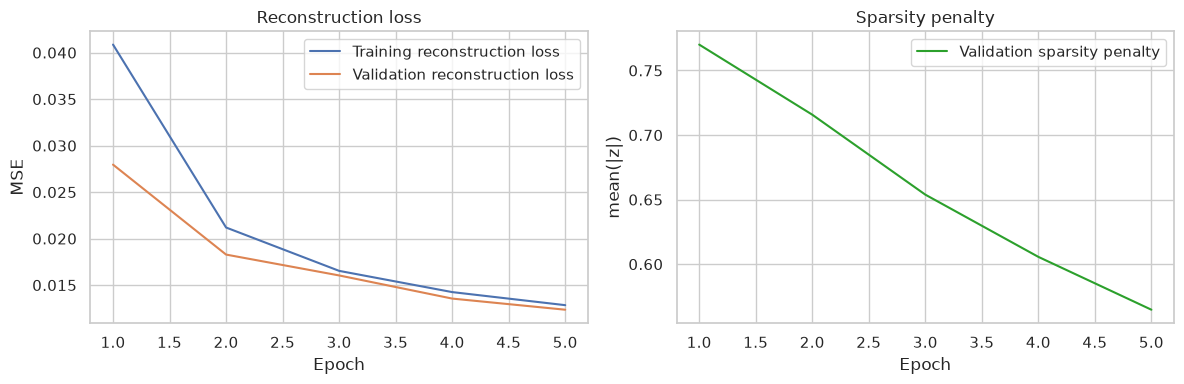

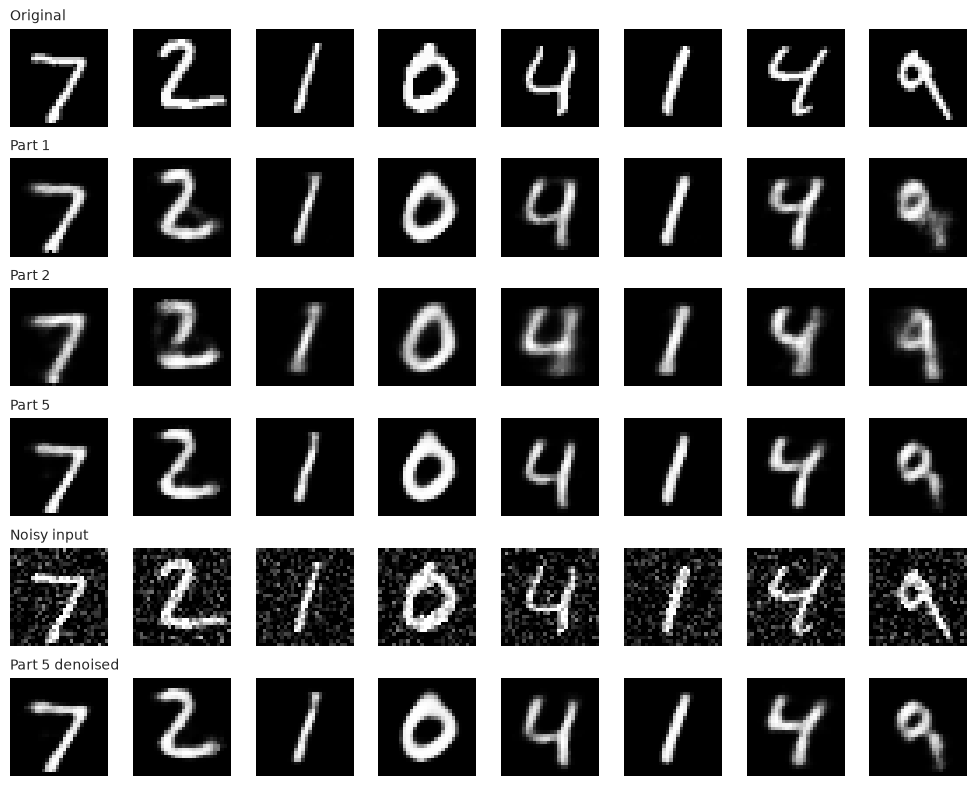

In [18]:
# Part 5: plot the tracked curves
epochs = range(1, len(advanced_history["train_reconstruction_loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, advanced_history["train_reconstruction_loss"], label="Training reconstruction loss")
plt.plot(epochs, advanced_history["val_reconstruction_loss"], label="Validation reconstruction loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Reconstruction loss")
plt.legend()

# the sparsity penalty is on a different scale, so it gets its own plot
plt.subplot(1, 2, 2)
plt.plot(epochs, advanced_history["val_sparsity_penalty"], color="tab:green", label="Validation sparsity penalty")
plt.xlabel("Epoch")
plt.ylabel("mean(|z|)")
plt.title("Sparsity penalty")
plt.legend()
plt.tight_layout()
plt.show()


# Part 5: compare reconstructions of Part 1, Part 2 and Part 5 on the same validation images
images, _ = next(iter(validation_dataloader))
images_flat = images[:8].view(8, -1)
noisy_flat = add_gaussian_noise(images_flat, noise_std=0.2)

autoencoder.eval()
autoencoder_with_classifier.eval()
advanced_autoencoder.eval()
with torch.no_grad():
    part1_recon = autoencoder(images_flat)
    part2_recon, _ = autoencoder_with_classifier(images_flat)
    part5_recon, _ = advanced_autoencoder(images_flat)
    part5_denoised, _ = advanced_autoencoder(noisy_flat)

rows = [
    ("Original", images_flat),
    ("Part 1", part1_recon),
    ("Part 2", part2_recon),
    ("Part 5", part5_recon),
    ("Noisy input", noisy_flat),
    ("Part 5 denoised", part5_denoised),
]

fig, axes = plt.subplots(len(rows), 8, figsize=(10, 8))
for r, (title, imgs) in enumerate(rows):
    for col in range(8):
        axes[r, col].imshow(imgs[col].view(28, 28).cpu(), cmap="gray")
        axes[r, col].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10)
plt.tight_layout()
plt.show()


# Part 6: Skip-gram Word2Vec from scratch (20 points total)

In this part, you will implement **Skip-gram Word2Vec** in two versions.

## Goal

Learn embeddings so that words appearing in similar contexts have similar vectors.

## Shared setup (for both subparts)

1. Build a simple text preprocessing pipeline:
   - lowercase
   - remove punctuation (optional but recommended)
   - split into tokens
2. Build vocabulary dictionaries:
   - `word_to_ix`
   - `ix_to_word`
3. Create skip-gram `(center_word, context_word)` training pairs using a context window.
4. Implement a `Dataset`/`DataLoader` for pairs.

## Part 6A: Full Softmax (10 points)

Implement skip-gram with a full-vocabulary softmax objective.

## Part 6B: Negative Sampling (10 points)

Implement skip-gram with negative sampling and compare training behavior against Part 6A.

Use small dimensions first (`embedding_dim=50`) to debug quickly.


In [ ]:
# Part 6 starter code (TODO assignment, no full solution)

import re
import time
from collections import Counter
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# Load an actual text dataset (AG News)
# If needed: pip install datasets
from datasets import load_dataset


def load_ag_news_corpus(max_train_samples=5000):
    # newer versions of `datasets` need the full repository name
    ds = load_dataset("fancyzhx/ag_news", split=f"train[:{max_train_samples}]")
    texts = [row["text"] for row in ds]
    return "\n".join(texts)


text_corpus = load_ag_news_corpus(max_train_samples=5000)
print(f"Loaded AG News corpus with {len(text_corpus.split())} tokens (before preprocessing)")


def preprocess_text(text):
    # TODO 1: improve preprocessing if needed
    text = text.lower()
    # AG News contains HTML links like &lt;a href="http://...quickinfo..."&gt;, remove them
    # so that words like "href", "http", "quickinfo" do not end up in the vocabulary
    text = re.sub(r"&lt;.*?&gt;", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"&\w+;|#\d+;", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    return tokens


def build_vocab(tokens, min_freq=1):
    # TODO 2: create word_counts, vocab, word_to_ix, ix_to_word
    word_counts = Counter(tokens)
    # most frequent words first; rare words (count < min_freq) are dropped
    vocab = [word for word, count in word_counts.most_common() if count >= min_freq]
    word_to_ix = {word: ix for ix, word in enumerate(vocab)}
    ix_to_word = {ix: word for word, ix in word_to_ix.items()}
    return word_counts, vocab, word_to_ix, ix_to_word


def build_skipgram_pairs(tokens, word_to_ix, window_size=2):
    # TODO 3: build (center, context) pairs
    # words that are not in the vocabulary are removed first
    ids = [word_to_ix[word] for word in tokens if word in word_to_ix]
    pairs = []
    for i, center in enumerate(ids):
        start = max(0, i - window_size)
        end = min(len(ids), i + window_size + 1)
        for j in range(start, end):
            if j != i:
                pairs.append((center, ids[j]))
    return pairs


class SkipGramDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        center, context = self.pairs[idx]
        return torch.tensor(center, dtype=torch.long), torch.tensor(context, dtype=torch.long)


# Shared setup
tokens = preprocess_text(text_corpus)
word_counts, vocab, word_to_ix, ix_to_word = build_vocab(tokens, min_freq=5)
pairs = build_skipgram_pairs(tokens, word_to_ix, window_size=2)
skipgram_dataset = SkipGramDataset(pairs)
skipgram_dataloader = DataLoader(skipgram_dataset, batch_size=256, shuffle=True)
print(f"Vocabulary size: {len(vocab)} | Number of pairs: {len(pairs)}")


# -----------------------------
# Part 6A: Full Softmax (10 pts)
# -----------------------------
class SkipGramSoftmax(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.in_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.out_linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_words):
        # TODO 4: return logits of shape [B, vocab_size]
        # Hint: center -> embedding -> linear projection to vocab size
        center_vectors = self.in_embeddings(center_words)   # [B, D]
        logits = self.out_linear(center_vectors)            # [B, vocab_size]
        return logits


def train_skipgram_softmax(model, dataloader, num_epochs=10, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {"loss": [], "epoch_time": []}

    for epoch in range(num_epochs):
        total_loss = 0.0
        start_time = time.time()
        for center_batch, context_batch in dataloader:
            # TODO 5: complete training step for full softmax
            # 1) zero gradients
            # 2) logits = model(center_batch)
            # 3) loss = criterion(logits, context_batch)
            # 4) backward + optimizer step
            # 5) accumulate total_loss
            optimizer.zero_grad()
            logits = model(center_batch)
            loss = criterion(logits, context_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * center_batch.size(0)

        avg_loss = total_loss / len(dataloader.dataset)
        epoch_time = time.time() - start_time
        history["loss"].append(avg_loss)
        history["epoch_time"].append(epoch_time)
        print(f"[Softmax] Epoch {epoch + 1}/{num_epochs} - Loss: {avg_loss:.4f} - Time: {epoch_time:.1f}s")

    return history


# -----------------------------------
# Part 6B: Negative Sampling (10 pts)
# -----------------------------------
class SkipGramNegativeSampling(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.target_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.context_embeddings = nn.Embedding(vocab_size, embedding_dim)

        nn.init.xavier_uniform_(self.target_embeddings.weight)
        nn.init.xavier_uniform_(self.context_embeddings.weight)

    def forward(self, center_words, pos_context_words, neg_context_words):
        # TODO 6: implement negative sampling loss
        # Expected shapes:
        # center_words: [B], pos_context_words: [B], neg_context_words: [B, K]
        # Hint:
        # - positive term: log sigma(v_c . v_o)
        # - negative term: sum_k log sigma(-v_c . v_nk)
        v_c = self.target_embeddings(center_words)        # [B, D]
        u_o = self.context_embeddings(pos_context_words)  # [B, D]
        u_neg = self.context_embeddings(neg_context_words)  # [B, K, D]

        pos_score = torch.sum(v_c * u_o, dim=1)                          # [B]
        neg_score = torch.bmm(u_neg, v_c.unsqueeze(2)).squeeze(2)        # [B, K]

        # logsigmoid is a numerically stable log(sigmoid(x))
        pos_term = F.logsigmoid(pos_score)                # [B]
        neg_term = F.logsigmoid(-neg_score).sum(dim=1)    # [B]

        # we maximise pos_term + neg_term, so the loss is its negative (averaged over the batch)
        loss = -(pos_term + neg_term).mean()
        return loss


def sample_negative(batch_size, num_negatives, dist):
    # TODO 7: sample negative word indices using the given distribution
    # Output shape should be [batch_size, num_negatives]
    negatives = torch.multinomial(dist, batch_size * num_negatives, replacement=True)
    return negatives.view(batch_size, num_negatives)


def train_skipgram_negative_sampling(
    model,
    dataloader,
    neg_sampling_dist,
    num_negatives=5,
    num_epochs=10,
    learning_rate=1e-3,
):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {"loss": [], "epoch_time": []}

    for epoch in range(num_epochs):
        total_loss = 0.0
        start_time = time.time()
        for center_batch, context_batch in dataloader:
            batch_size = center_batch.size(0)
            negative_batch = sample_negative(batch_size, num_negatives, neg_sampling_dist)

            # TODO 8: complete training step for negative sampling
            # 1) zero gradients
            # 2) loss = model(center_batch, context_batch, negative_batch)
            # 3) backward + optimizer step
            # 4) accumulate total_loss
            optimizer.zero_grad()
            loss = model(center_batch, context_batch, negative_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch_size

        avg_loss = total_loss / len(dataloader.dataset)
        epoch_time = time.time() - start_time
        history["loss"].append(avg_loss)
        history["epoch_time"].append(epoch_time)
        print(f"[NegSampling] Epoch {epoch + 1}/{num_epochs} - Loss: {avg_loss:.4f} - Time: {epoch_time:.1f}s")

    return history


# Build unigram distribution^(3/4) for negative sampling
unigram = torch.tensor([word_counts[ix_to_word[i]] for i in range(len(vocab))], dtype=torch.float)
neg_sampling_dist = unigram.pow(0.75)
neg_sampling_dist = neg_sampling_dist / neg_sampling_dist.sum()


# TODO 9 and TODO 10 are implemented in the cells below


Loaded AG News corpus with 195904 tokens (before preprocessing)
Vocabulary size: 4794 | Number of pairs: 709046


In [20]:
# TODO 9: run both models and compare training curves
torch.manual_seed(0)

softmax_model = SkipGramSoftmax(vocab_size=len(vocab), embedding_dim=50)
softmax_history = train_skipgram_softmax(softmax_model, skipgram_dataloader, num_epochs=10, learning_rate=1e-2)

neg_model = SkipGramNegativeSampling(vocab_size=len(vocab), embedding_dim=50)
neg_history = train_skipgram_negative_sampling(
    neg_model,
    skipgram_dataloader,
    neg_sampling_dist,
    num_negatives=5,
    num_epochs=10,
    learning_rate=1e-2,
)


[Softmax] Epoch 1/10 - Loss: 6.8008 - Time: 24.8s
[Softmax] Epoch 2/10 - Loss: 6.3518 - Time: 22.2s
[Softmax] Epoch 3/10 - Loss: 6.2228 - Time: 23.5s
[Softmax] Epoch 4/10 - Loss: 6.1674 - Time: 24.1s
[Softmax] Epoch 5/10 - Loss: 6.1391 - Time: 24.9s
[Softmax] Epoch 6/10 - Loss: 6.1223 - Time: 23.3s
[Softmax] Epoch 7/10 - Loss: 6.1121 - Time: 23.5s
[Softmax] Epoch 8/10 - Loss: 6.1042 - Time: 24.3s
[Softmax] Epoch 9/10 - Loss: 6.0997 - Time: 23.8s
[Softmax] Epoch 10/10 - Loss: 6.0951 - Time: 23.4s
[NegSampling] Epoch 1/10 - Loss: 2.4868 - Time: 12.6s
[NegSampling] Epoch 2/10 - Loss: 2.2375 - Time: 11.1s
[NegSampling] Epoch 3/10 - Loss: 2.1682 - Time: 11.0s
[NegSampling] Epoch 4/10 - Loss: 2.1422 - Time: 11.1s
[NegSampling] Epoch 5/10 - Loss: 2.1281 - Time: 11.3s
[NegSampling] Epoch 6/10 - Loss: 2.1197 - Time: 12.8s
[NegSampling] Epoch 7/10 - Loss: 2.1150 - Time: 12.1s
[NegSampling] Epoch 8/10 - Loss: 2.1110 - Time: 12.3s
[NegSampling] Epoch 9/10 - Loss: 2.1095 - Time: 12.6s
[NegSampling]

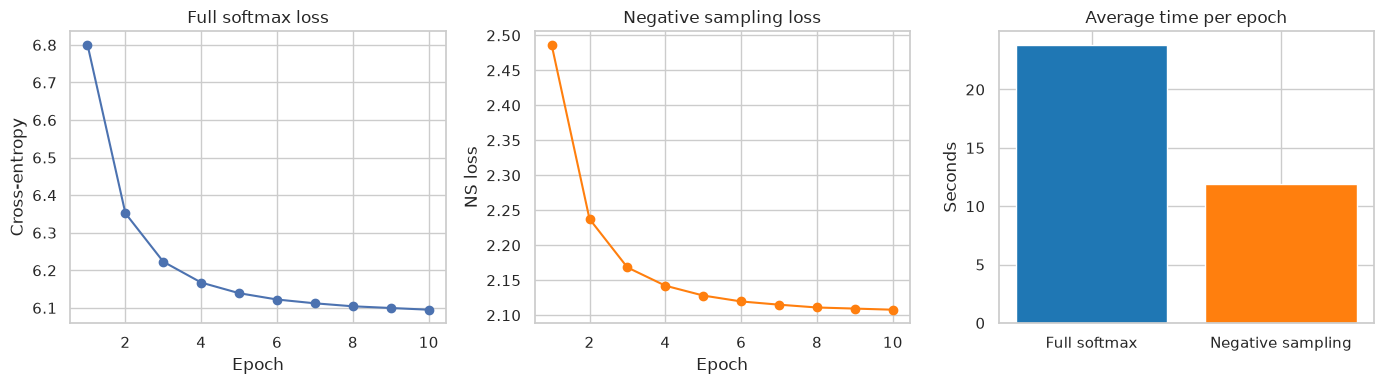

Vocabulary size: 4794
Full softmax:      23.8s per epoch
Negative sampling: 11.9s per epoch


In [21]:
# Training curves and time per epoch
# Note: the two losses are different objectives (cross-entropy over the whole vocabulary
# vs. 1 positive + 5 negative binary terms), so their values cannot be compared directly,
# only how they decrease over the epochs.
epochs = range(1, len(softmax_history["loss"]) + 1)

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.plot(epochs, softmax_history["loss"], marker="o")
plt.title("Full softmax loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy")

plt.subplot(1, 3, 2)
plt.plot(epochs, neg_history["loss"], marker="o", color="tab:orange")
plt.title("Negative sampling loss")
plt.xlabel("Epoch")
plt.ylabel("NS loss")

plt.subplot(1, 3, 3)
plt.bar(["Full softmax", "Negative sampling"],
        [np.mean(softmax_history["epoch_time"]), np.mean(neg_history["epoch_time"])],
        color=["tab:blue", "tab:orange"])
plt.title("Average time per epoch")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

print(f"Vocabulary size: {len(vocab)}")
print(f"Full softmax:      {np.mean(softmax_history['epoch_time']):.1f}s per epoch")
print(f"Negative sampling: {np.mean(neg_history['epoch_time']):.1f}s per epoch")


In [ ]:
# TODO 10: helper to inspect nearest neighbors and compare both variants
# (also covers bonus question 5: cosine similarity vs raw dot product)

def nearest_neighbors(embeddings, word, word_to_ix, ix_to_word, k=5, metric="cosine"):
    if word not in word_to_ix:
        return None
    embeddings = embeddings.detach()
    if metric == "cosine":
        # normalise every vector to length 1, then the dot product is the cosine similarity
        embeddings = F.normalize(embeddings, dim=1)
    query = embeddings[word_to_ix[word]]
    scores = embeddings @ query
    scores[word_to_ix[word]] = -float("inf")   # do not return the word itself
    top = torch.topk(scores, k).indices.tolist()
    return [ix_to_word[ix] for ix in top]


# for both models we use the "input" (center word) embeddings as the word vectors
softmax_vectors = softmax_model.in_embeddings.weight
neg_vectors = neg_model.target_embeddings.weight

query_words = ["monday", "oil", "iraq", "game", "software", "president", "stocks"]

for word in query_words:
    print(f"{word}")
    print(f"  softmax  (cosine): {nearest_neighbors(softmax_vectors, word, word_to_ix, ix_to_word)}")
    print(f"  neg samp (cosine): {nearest_neighbors(neg_vectors, word, word_to_ix, ix_to_word)}")
    print(f"  neg samp (dot)   : {nearest_neighbors(neg_vectors, word, word_to_ix, ix_to_word, metric='dot')}")


monday
  softmax  (cosine): ['tuesday', 'friday', 'thursday', 'wednesday', 'yesterday']
  neg samp (cosine): ['thursday', 'tuesday', 'wednesday', 'friday', 'yesterday']
  neg samp (dot)   : ['reliever', 'splashing', 'fre', 'exclusively', 'archaeologists']
oil
  softmax  (cosine): ['crude', 'prices', 'record', 'commodities', 'futures']
  neg samp (cosine): ['prices', 'futures', 'commodities', 'crude', 'worries']
  neg samp (dot)   : ['raced', 'commodities', 'slumping', 'escalating', 'encouraged']
iraq
  softmax  (cosine): ['baghdad', 'najaf', 'iraqi', 'troops', 'rages']
  neg samp (cosine): ['najaf', 'baghdad', 'iraqi', 'israel', 'gunfire']
  neg samp (dot)   : ['unabated', 'abuse', 'rages', 'parade', 'gunfire']
game
  softmax  (cosine): ['video', 'football', 'protests', 'pattern', 'ers']
  neg samp (cosine): ['video', 'format', 'play', 'plays', 'blue']
  neg samp (dot)   : ['typical', 'narrower', 'clearing', 'franchise', 'doubleheader']
software
  softmax  (cosine): ['releases', 'syste

In [24]:
# Question 4: train on a larger English corpus (more AG News articles) and compare neighbors
# Only negative sampling is used here, because full softmax would be much slower.
big_corpus = load_ag_news_corpus(max_train_samples=20000)
big_tokens = preprocess_text(big_corpus)
big_word_counts, big_vocab, big_word_to_ix, big_ix_to_word = build_vocab(big_tokens, min_freq=5)
big_pairs = build_skipgram_pairs(big_tokens, big_word_to_ix, window_size=2)

# TensorDataset is faster than building two tensors per pair for millions of pairs
big_dataloader = DataLoader(
    torch.utils.data.TensorDataset(*torch.tensor(big_pairs, dtype=torch.long).unbind(1)),
    batch_size=1024,
    shuffle=True,
)
print(f"Large corpus: {len(big_tokens)} tokens | vocabulary: {len(big_vocab)} | pairs: {len(big_pairs)}")

big_unigram = torch.tensor([big_word_counts[big_ix_to_word[i]] for i in range(len(big_vocab))], dtype=torch.float)
big_neg_sampling_dist = big_unigram.pow(0.75)
big_neg_sampling_dist = big_neg_sampling_dist / big_neg_sampling_dist.sum()

torch.manual_seed(0)
big_neg_model = SkipGramNegativeSampling(vocab_size=len(big_vocab), embedding_dim=50)
big_neg_history = train_skipgram_negative_sampling(
    big_neg_model,
    big_dataloader,
    big_neg_sampling_dist,
    num_negatives=5,
    num_epochs=3,
    learning_rate=1e-2,
)

for word in query_words:
    print(f"{word}")
    print(f"  5000 articles : {nearest_neighbors(neg_vectors, word, word_to_ix, ix_to_word)}")
    print(f"  20000 articles: {nearest_neighbors(big_neg_model.target_embeddings.weight, word, big_word_to_ix, big_ix_to_word)}")


Large corpus: 768957 tokens | vocabulary: 11182 | pairs: 2945958
[NegSampling] Epoch 1/3 - Loss: 2.3841 - Time: 33.5s
[NegSampling] Epoch 2/3 - Loss: 2.1987 - Time: 34.0s
[NegSampling] Epoch 3/3 - Loss: 2.1615 - Time: 34.3s
monday
  5000 articles : ['thursday', 'tuesday', 'wednesday', 'friday', 'yesterday']
  20000 articles: ['friday', 'tuesday', 'thursday', 'wednesday', 'today']
oil
  5000 articles : ['prices', 'futures', 'commodities', 'crude', 'worries']
  20000 articles: ['crude', 'prices', 'flows', 'skyrocketing', 'yukos']
iraq
  5000 articles : ['najaf', 'baghdad', 'iraqi', 'israel', 'gunfire']
  20000 articles: ['baghdad', 'najaf', 'iraqi', 'basra', 'shrine']
game
  5000 articles : ['video', 'format', 'play', 'plays', 'blue']
  20000 articles: ['series', 'games', 'video', 'round', 'match']
software
  5000 articles : ['antivirus', 'technology', 'antispyware', 'systems', 'management']
  20000 articles: ['tool', 'tools', 'apps', 'desktop', 'enterprise']
president
  5000 articles : 

## Part 6 Questions (included in Part 6 points)

1. Why do we use two embedding matrices in skip-gram training?
2. Why is negative sampling computationally more efficient than full softmax for large vocabularies?
3. How does context window size affect the type of semantic/syntactic relationships captured?
4. Replace the toy corpus with a larger Armenian or English corpus and compare nearest-neighbor quality.
5. (Bonus) Implement cosine-similarity-based nearest neighbors and compare against raw dot product.
